In [1]:
import sys

print(sys.version)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [5]:
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [6]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

print("All Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
NumPy Version: 2.3.5
All Libraries Imported Successfully!


In [10]:
import os

dataset_path = r"C:\Users\Ancy\Downloads\archive"

print(os.listdir(dataset_path))

['seg_pred', 'seg_test', 'seg_train']


In [ ]:
#Step 3 – Explore Dataset

In [11]:
import os

train_path = os.path.join(dataset_path, "seg_train", "seg_train")

print(os.listdir(train_path))

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
#Step 3.2 – Count Images in Each Class

In [12]:
classes = os.listdir(train_path)

for class_name in classes:
    folder_path = os.path.join(train_path, class_name)
    total_images = len(os.listdir(folder_path))

    print(class_name, ":", total_images)

buildings : 2191
forest : 2271
glacier : 2404
mountain : 2512
sea : 2274
street : 2382


In [ ]:
#Step 3.3 – Display Sample Images

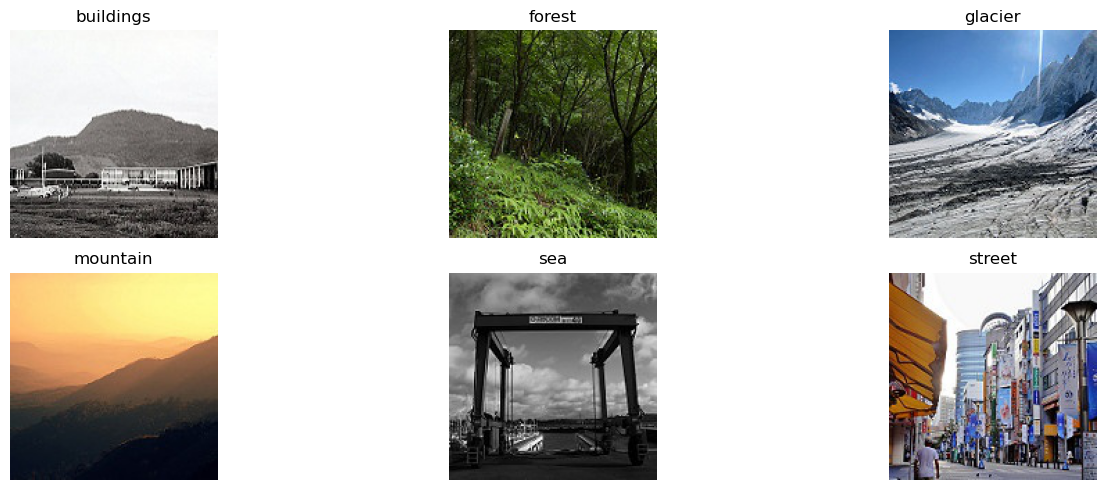

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import os

plt.figure(figsize=(15, 5))

for i, class_name in enumerate(classes):
    folder_path = os.path.join(train_path, class_name)

    image_name = os.listdir(folder_path)[0]
    image_path = os.path.join(folder_path, image_name)

    img = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#Step 4 – Image Size Checking

In [14]:
image_name = os.listdir(train_path + "/buildings")[0]

image_path = os.path.join(train_path, "buildings", image_name)

img = Image.open(image_path)

print("Image Size:", img.size)

Image Size: (150, 150)


In [ ]:
#Load Training Images

In [16]:
X_train = []
y_train = []

for class_name in classes:
    folder_path = os.path.join(train_path, class_name)

    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)

        img = Image.open(image_path).convert("RGB")
        img = img.resize((150, 150))

        X_train.append(np.array(img))
        y_train.append(classes.index(class_name))

print("Training images loaded successfully!")
print("Total Images:", len(X_train))

Training images loaded successfully!
Total Images: 14034


In [ ]:
#Convert Images into NumPy Array

In [17]:
X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

X_train Shape: (14034, 150, 150, 3)
y_train Shape: (14034,)


In [19]:
print("Data Type:", X_train.dtype)
print("Shape:", X_train.shape)

Data Type: uint8
Shape: (14034, 150, 150, 3)


In [21]:
import gc

del X_train
del y_train

gc.collect()

print("Memory cleared!")

Memory cleared!


In [ ]:
Load Training Dataset

In [22]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(150, 150),
    batch_size=32,
    label_mode="int",
    shuffle=True
)

print("Training dataset loaded successfully!")

Found 14034 files belonging to 6 classes.
Training dataset loaded successfully!


In [ ]:
Check Class Names

In [23]:
class_names = train_dataset.class_names

print("Class Names:", class_names)
print("Number of Classes:", len(class_names))

Class Names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of Classes: 6


In [ ]:
Display Sample Images

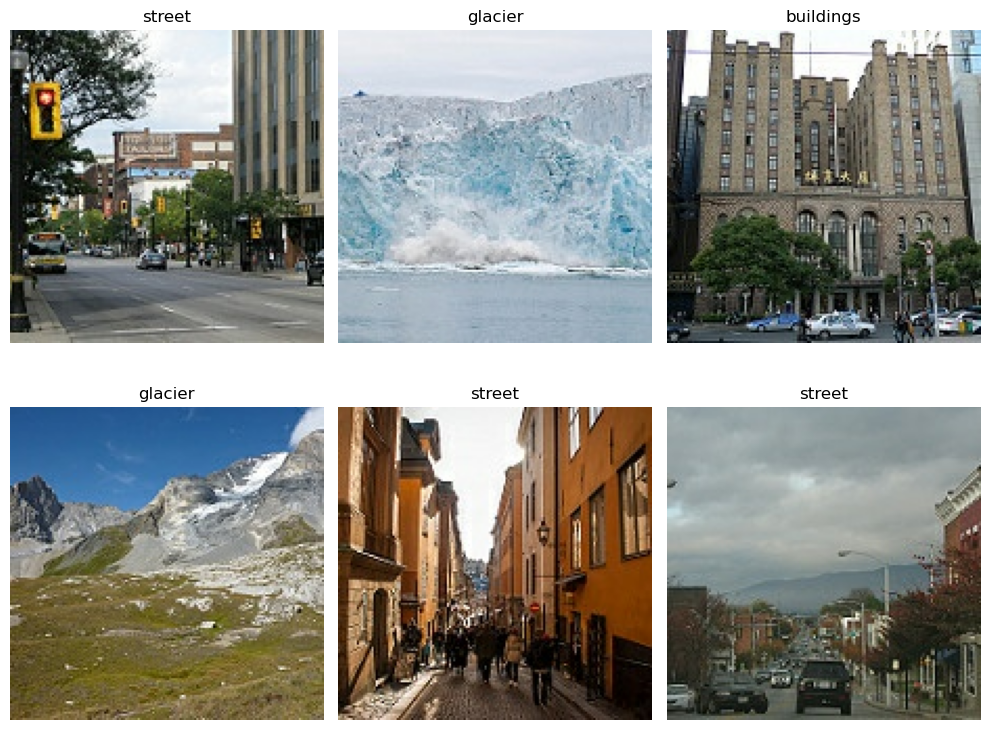

In [24]:
plt.figure(figsize=(10, 8))

for images, labels in train_dataset.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()

In [ ]:
Load Validation Dataset

In [25]:
test_path = os.path.join(dataset_path, "seg_test", "seg_test")

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(150, 150),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("Validation dataset loaded successfully!")

Found 3000 files belonging to 6 classes.
Validation dataset loaded successfully!


In [ ]:
Normalize Images

In [26]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Normalization completed!")

Normalization completed!


In [ ]:
Build CNN Model

In [27]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(6, activation="softmax")
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [ ]:
Compile the CNN Model

In [28]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [ ]:
Train CNN Model

In [29]:
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=5
)

Epoch 1/5


C:\Users\Ancy\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 ━━━━━━━━━━━━━━━━━━━━ 205s 462ms/step - accuracy: 0.5817 - loss: 1.0668 - val_accuracy: 0.6773 - val_loss: 0.8394
Epoch 2/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 202s 461ms/step - accuracy: 0.7110 - loss: 0.7793 - val_accuracy: 0.7810 - val_loss: 0.6110
Epoch 3/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 209s 475ms/step - accuracy: 0.7859 - loss: 0.6018 - val_accuracy: 0.7847 - val_loss: 0.5704
Epoch 4/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 203s 462ms/step - accuracy: 0.8199 - loss: 0.5050 - val_accuracy: 0.8140 - val_loss: 0.5029
Epoch 5/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 201s 458ms/step - accuracy: 0.8560 - loss: 0.4088 - val_accuracy: 0.8267 - val_loss: 0.4945


In [ ]:
Model Evaluation

In [30]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - accuracy: 0.8267 - loss: 0.4945
Test Loss: 0.49447616934776306
Test Accuracy: 0.8266666531562805


In [ ]:
Confusion Matrix

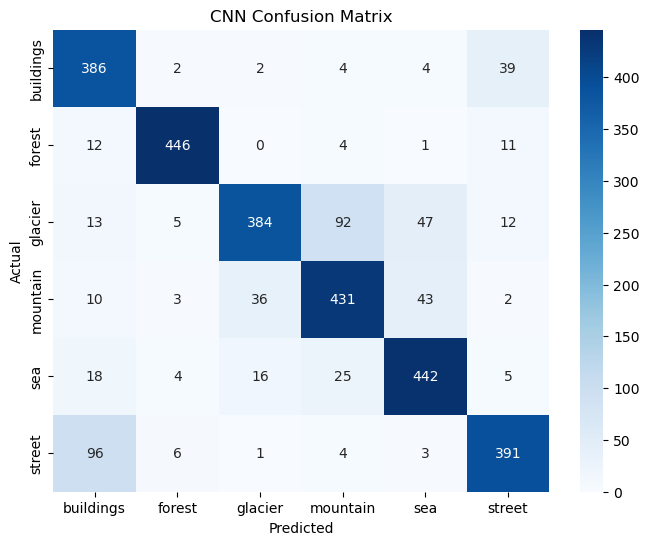

In [36]:
from sklearn.metrics import confusion_matrix
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

In [ ]:
Classification Report

In [38]:
from sklearn.metrics import classification_report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

   buildings       0.72      0.88      0.79       437
      forest       0.96      0.94      0.95       474
     glacier       0.87      0.69      0.77       553
    mountain       0.77      0.82      0.79       525
         sea       0.82      0.87      0.84       510
      street       0.85      0.78      0.81       501

    accuracy                           0.83      3000
   macro avg       0.83      0.83      0.83      3000
weighted avg       0.83      0.83      0.83      3000



In [ ]:
Training Graph

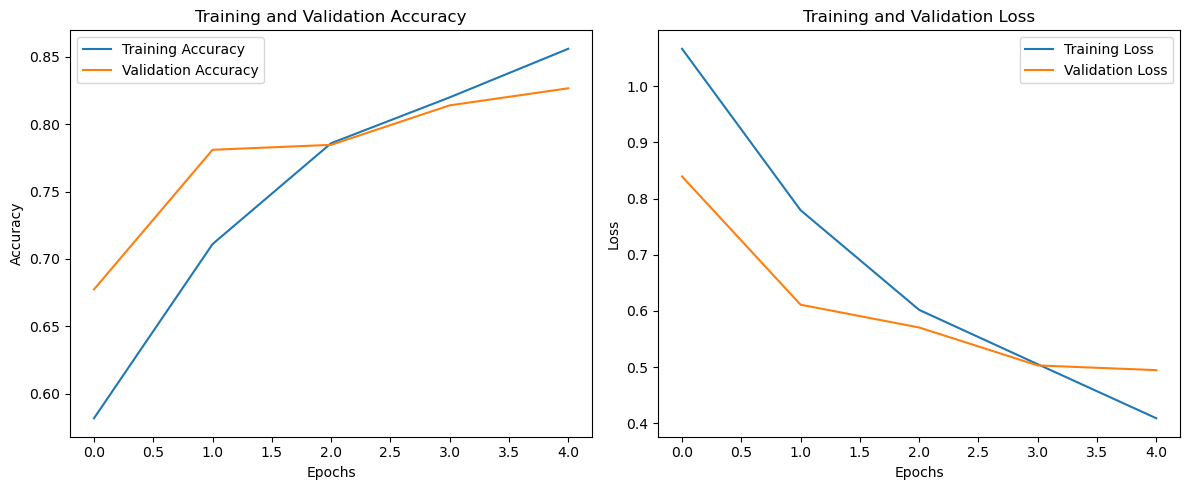

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
Model Save

In [40]:
model.save("cnn_image_classification_model.keras")

print("Model saved successfully!")

Model saved successfully!
